## PREDICCIÓN DE GLUCOSA CON RED LSTM APILADA A 30 MINUTOS (PyTorch): MODELO MULTIVARIADO (3 CANALES) - UNISTEP
## Réplica de la arquitectura de Rabby et al. (2021), *BMC Med Inform Decis Mak* — canales glucosa + insulina en bolo efectiva + carbohidratos efectivos
**Paciente n001 · Horizonte de predicción de 30 minutos (6 pasos de 5 minutos, una sola salida)**

## Contenido

1. Introducción
2. Conjunto de datos
3. Problema: Predicción de glucosa a 30 minutos
4. Lectura del conjunto de datos
5. Pre-procesamiento
6. Definición y entrenamiento del modelo
7. Desempeño del modelo
8. Predicciones con el modelo entrenado
9. Referencias

## 1. Introducción

Este cuaderno implementa en **PyTorch** la arquitectura de red propuesta por **Rabby et al. (2021)** — *"Stacked LSTM based deep recurrent neural network with Kalman smoothing for blood glucose prediction"* — para pronosticar la glucosa a futuro a partir de lecturas CGM suavizadas con el filtro de Kalman, la insulina en bolo efectiva y los carbohidratos efectivos.

**Arquitectura replicada (Figura 1):**

- 2 capas **LSTM apiladas** (*stacked*) de 128 unidades cada una.
- Una capa de **dropout** entre la primera y la segunda capa LSTM.
- Una red totalmente conectada de 3 capas a la salida: `Dense(512, ReLU)` → `Dense(128, ReLU)` → `Dense(1)`.
- Optimizador **Adam**, tasa de aprendizaje `1e-3`, `batch_size = 128`, y *early stopping* con paciencia de 128 épocas (hasta un máximo de 2000).

**Diferencia con el artículo original:** Rabby et al. usan **4 canales de entrada** (CGM suavizado, carbohidratos de la comida, insulina bolus e información de pasos). Este cuaderno es una versión **de 3 canales**: CGM suavizado con Kalman, insulina en bolo efectiva y carbohidratos efectivos.

*Multivariado (3 canales)*: el modelo usa como entrada el historial de glucosa + insulina en bolo efectiva + carbohidratos efectivos. La salida es solo glucosa.
*Unistep*: el modelo entrega **un solo valor**: la glucosa 30 minutos (6 pasos de 5 min) después del último dato de la entrada.

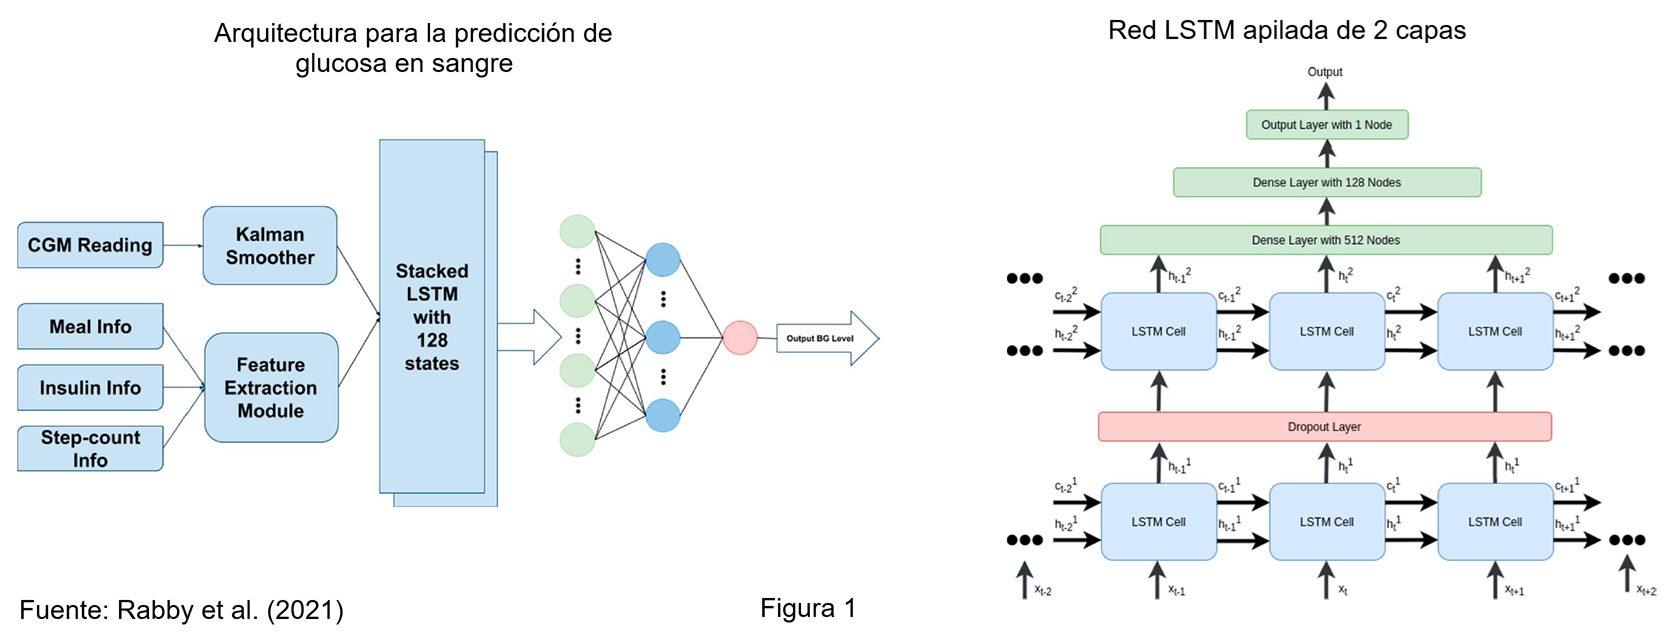

## 2. Conjunto de datos (datasets)

Se usan los datasets del paciente indicado en `PACIENTE`, sincronizados a una frecuencia de **5 minutos**, que ya incluyen las variables de insulina en bolo y carbohidratos efectivos:

- `{PACIENTE}-dataset-train-smoothed-ieef-ceff.xlsx`: datos para entrenamiento y validación
- `{PACIENTE}-dataset-test-smoothed-ieef-ceff.xlsx`: datos de prueba (nunca vistos durante el entrenamiento)

Las columnas `insulina_u` y `carbohidratos_g` (dosis y gramos en el instante del evento) no se usan directamente: el modelo recibe la insulina en bolo efectiva y los carbohidratos efectivos.

La serie puede tener **huecos** (cortes entre segmentos en los que no hay lecturas). La celda de lectura muestra los intervalos entre lecturas para verificarlo. Los huecos se respetan en dos lugares: en los gráficos (no se unen con una línea, función `con_cortes`) y al generar las ventanas (ninguna ventana cruza un hueco).

## 3. Problema: Predicción de glucosa a 30 minutos

Con los últimos `INPUT_LENGTH` = 24 valores de glucosa + insulina en bolo efectiva + carbohidratos efectivos (**2 horas**, uno cada 5 min) se predice la glucosa en el instante **t + 30 min** (6 pasos hacia adelante):

```
Entrada:  [g(t-23), Ieff(t-23), Ceff(t-23)], ..., [g(t), Ieff(t), Ceff(t)]   -> 24 x 3
salida:   g(t+6)                                                            -> 1 x 1     (t+6 pasos de 5 min = 30 min)
```

Salida: valor de glucosa a 30 min.

Los pasos se calculan a partir de `PASO_MIN`, `HISTORIA_MIN` y `HORIZONTE_MIN` (celda de configuración).

## 4. Lectura del conjunto de datos

Los datasets se cargan en Colab desde Google Drive con:

`'drive'`: monta Google Drive y lee los archivos desde `RUTA`.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import MinMaxScaler

# ---------------- Configuración ----------------
PACIENTE = 'n001'                    # 'a001', 'a002', 'n001' o 'n002'
ORIGEN = 'drive'                     # 'drive' o 'subir'
RUTA = f'/gdrive/MyDrive/6_LSTM_DiabetesT1_Bolus_Carb_Pytorch/{PACIENTE}-smoothed/'   # carpeta con los .xlsx suavizados
RUTA_SALIDA = RUTA                   # carpeta donde se guardará el modelo entrenado

PASO_MIN = 5                         # minutos entre lecturas del sensor (datos sincronizados a 5 min)
HORIZONTE_MIN = 30                   # horizonte de predicción en minutos (Rabby et al.: PH = 30 y PH = 60)
HISTORIA_MIN = 120                   # historia de entrada en minutos (Rabby et al.: 120 min)
assert HORIZONTE_MIN % PASO_MIN == 0 and HISTORIA_MIN % PASO_MIN == 0, \
    'HORIZONTE_MIN e HISTORIA_MIN deben ser múltiplos de PASO_MIN'
HORIZONTE = HORIZONTE_MIN // PASO_MIN       # 6 pasos: se predice SOLO el instante t + HORIZONTE
INPUT_LENGTH = HISTORIA_MIN // PASO_MIN     # 24 lecturas = 2 horas de historia (hiperparámetro)
FREQ = pd.Timedelta(minutes=PASO_MIN)       # periodo de muestreo esperado (para detectar huecos)
print(f'PACIENTE={PACIENTE} | PASO_MIN={PASO_MIN} min | INPUT_LENGTH={INPUT_LENGTH} lecturas | HORIZONTE={HORIZONTE} pasos')

SEMILLA = 123
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Dispositivo: {DEVICE}  |  PyTorch {torch.__version__}')

# Reproducibilidad
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
torch.cuda.manual_seed_all(SEMILLA)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Colores. Definición del estilo de los gráficos
C_CRUDO, C_AZUL, C_NARANJA = '#898781', '#2a78d6', '#eb6834'
C_TINTA, C_TINTA_2, C_REJILLA = '#0b0b0b', '#52514e', '#e1e0d9'


def estilo(ax, titulo, ylabel='Glucosa (mg/dL)'):
    ax.set_title(titulo, loc='left', fontsize=12, color=C_TINTA)
    ax.set_ylabel(ylabel, color=C_TINTA_2)
    ax.grid(True, color=C_REJILLA, linewidth=0.8)
    ax.set_axisbelow(True)
    for lado in ('top', 'right'):
        ax.spines[lado].set_visible(False)
    for lado in ('left', 'bottom'):
        ax.spines[lado].set_color(C_REJILLA)
    ax.tick_params(colors=C_TINTA_2)

PACIENTE=n001 | PASO_MIN=5 min | INPUT_LENGTH=24 lecturas | HORIZONTE=6 pasos
Dispositivo: cuda  |  PyTorch 2.14.1+cu130


In [2]:
if ORIGEN == 'drive':
    from google.colab import drive
    drive.mount('/gdrive')
else:
    from google.colab import files
    files.upload()          # seleccionar {PACIENTE}-dataset-train-smoothed-ieef-ceff.xlsx y {PACIENTE}-dataset-test-smoothed-ieef-ceff.xlsx
    RUTA = RUTA_SALIDA = ''

df_train = pd.read_excel(RUTA + f'{PACIENTE}-dataset-train-smoothed-ieef-ceff.xlsx')
df_test = pd.read_excel(RUTA + f'{PACIENTE}-dataset-test-smoothed-ieef-ceff.xlsx')

# Ordenar por fecha y verificar el muestreo (lo esperado: intervalos de PASO_MIN minutos;
# cualquier otro intervalo corresponde a un hueco entre segmentos)
for df in (df_train, df_test):
    df['timestamp'] = pd.to_datetime(df['timestamp'])
df_train = df_train.sort_values('timestamp').reset_index(drop=True)
df_test = df_test.sort_values('timestamp').reset_index(drop=True)

print('Intervalos entre lecturas (train):')
print(df_train['timestamp'].diff().value_counts().head())
print('\nIntervalos entre lecturas (test):')
print(df_test['timestamp'].diff().value_counts().head())

intervalo_real = df_train['timestamp'].diff().mode()[0]
assert intervalo_real == FREQ, (
    f'El intervalo más frecuente de los datos es {intervalo_real}, pero PASO_MIN = {PASO_MIN} min. '
    'Ajusta PASO_MIN antes de continuar.')
print(f'\nOK: el muestreo de los datos coincide con PASO_MIN = {PASO_MIN} min\n')

print(f'train: {df_train.shape}   test: {df_test.shape}')
df_train.head()

Mounted at /gdrive
Intervalos entre lecturas (train):
timestamp
0 days 00:05:00    2888
0 days 02:05:00       1
0 days 03:50:00       1
Name: count, dtype: int64

Intervalos entre lecturas (test):
timestamp
0 days 00:05:00    732
0 days 08:15:00      1
Name: count, dtype: int64

OK: el muestreo de los datos coincide con PASO_MIN = 5 min

train: (2891, 11)   test: (734, 11)


,timestamp,segment_id,glucosa_raw,glucosa_kalman,glucosa_kalman_sd,is_outlier,is_imputed,insulina_u,carbohidratos_g,insulina_eff_u,carbohidratos_eff_g
0,2026-08-17 00:00:00,1,125.0,124.723238,8.936348,False,False,0.0,0,0.0,0.0
1,2026-08-17 00:05:00,1,129.0,130.059798,7.144417,False,False,0.0,0,0.0,0.0
2,2026-08-17 00:10:00,1,134.0,133.419044,6.405943,False,False,0.0,0,0.0,0.0
3,2026-08-17 00:15:00,1,135.0,134.707792,6.089798,False,False,0.0,0,0.0,0.0
4,2026-08-17 00:20:00,1,134.0,133.754649,6.023188,False,False,0.0,0,0.0,0.0


## 5. Pre-procesamiento

Incluye:

1. Partición en train / val / test
2. Creación de las ventanas de entrada y la salida del modelo
3. Escalamiento

Los datos **ya vienen separados en train y test** (el test es la continuación cronológica del train), así que:

- **test** = `{PACIENTE}-dataset-test-smoothed-ieef-ceff.xlsx`
- **train / val** = se divide `{PACIENTE}-dataset-train-smoothed-ieef-ceff.xlsx` en orden cronológico: primer 90 % para entrenar y último 10 % para validar.

### 5.1. Partición de datasets en entrenamiento, validación y prueba

En series de tiempo **no se deben mezclar aleatoriamente los datos** al generar las particiones:

- *train*: para encontrar los parámetros del modelo
- *val*: para verificar que no haya *under/over-fitting* y ajustar hiperparámetros
- *test*: para poner a prueba el mejor modelo encontrado

Tamaño set de entrenamiento: (2601, 3)
Tamaño set de validación: (290, 3)
Tamaño set de prueba: (734, 3)

Filas con valor distinto de 0 (canales de insulina/carbohidratos):
                     train  val  test
insulina_eff_u         697  127   312
carbohidratos_eff_g   1113  140   433


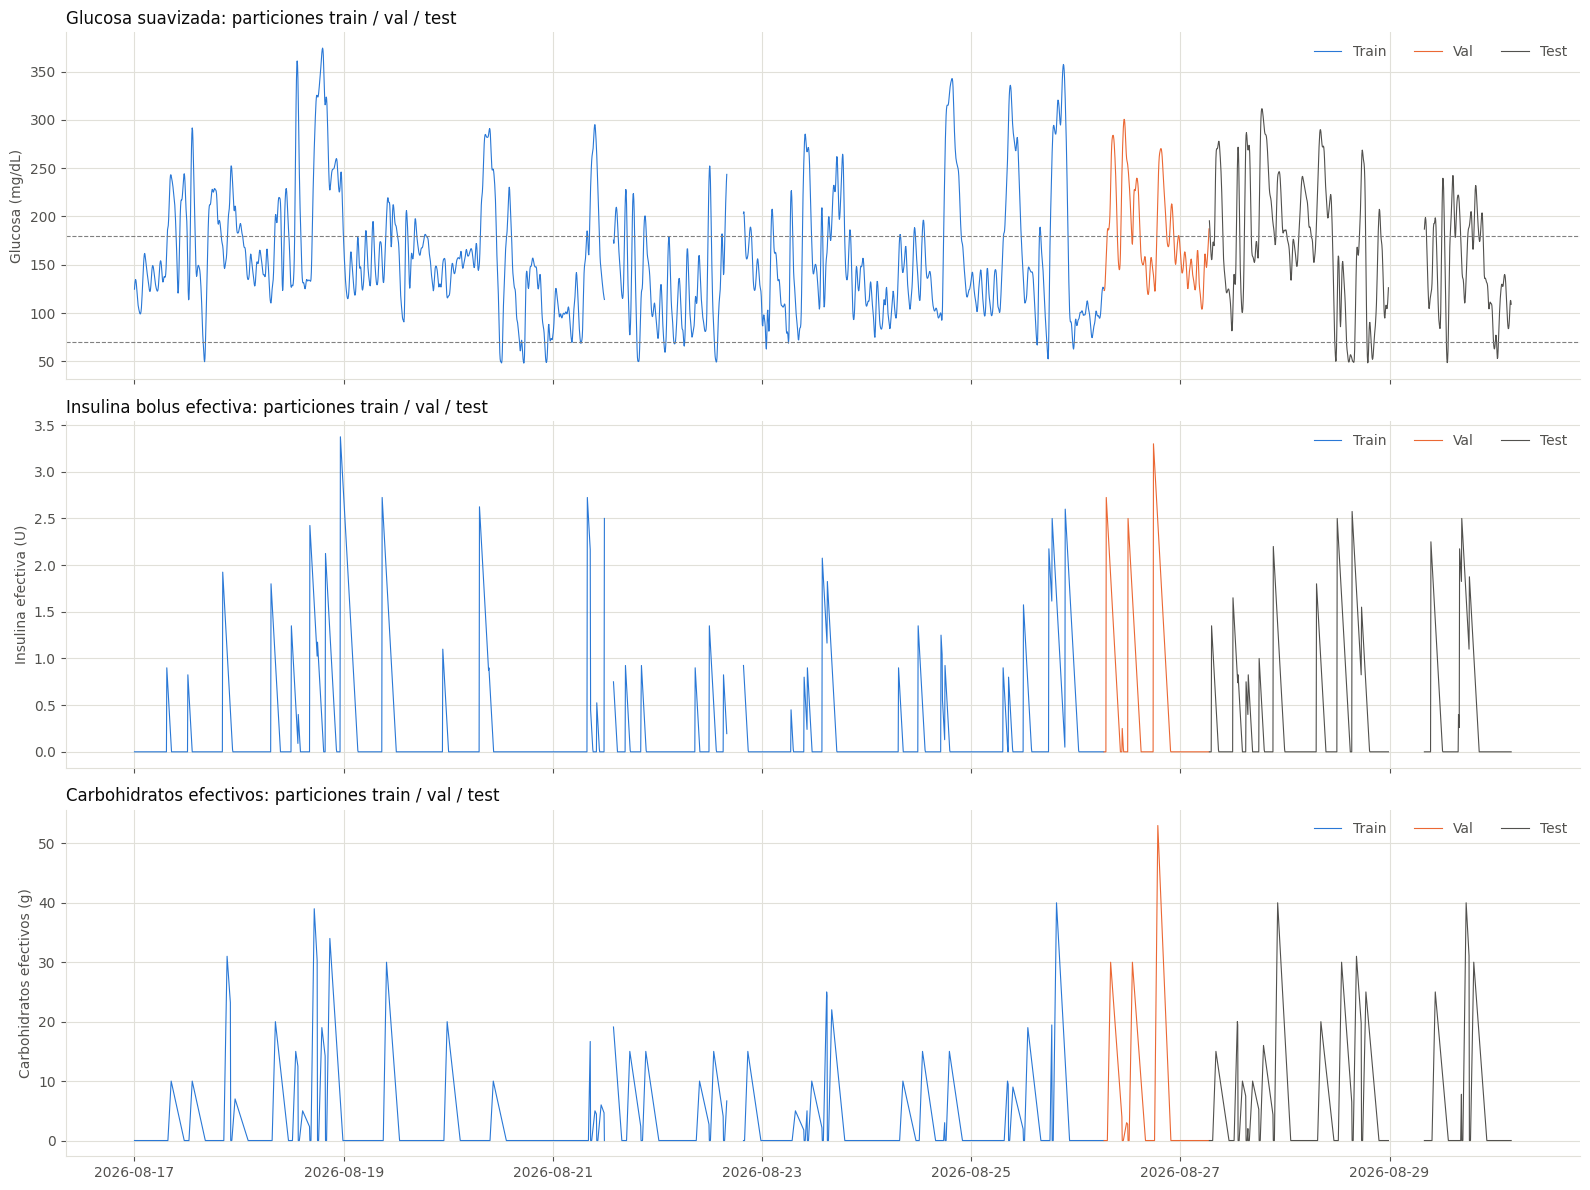

In [3]:
def train_val_split(df, vl_size=0.1):
    '''Partición cronológica (sin mezclar) en train y val.'''
    Ntrain = int((1 - vl_size) * len(df))         # número de filas que van al set de entrenamiento df_tr
    return df.iloc[:Ntrain].reset_index(drop=True), df.iloc[Ntrain:].reset_index(drop=True)


df_tr, df_vl = train_val_split(df_train, vl_size=0.1)
df_ts = df_test

COL = 'glucosa_kalman'          # glucosa suavizada: canal 0 y variable a predecir
COL_CRUDA = 'glucosa_raw'       # lectura cruda del sensor (solo para evaluar)
INS_COL = 'insulina_eff_u'      # insulina en bolo efectiva (ec. 3 de Rabby et al.)
CARB_COL = 'carbohidratos_eff_g'   # carbohidratos efectivos (ecs. 1-2 de Rabby et al.)
FEATURE_COLS = [COL, INS_COL, CARB_COL]   # canales de entrada (el canal 0 SIEMPRE es la glucosa)

faltan = [c for c in FEATURE_COLS + [COL_CRUDA] if c not in df_train.columns or c not in df_test.columns]
assert not faltan, f'Faltan columnas {faltan} en el dataset.'

# DataFrames con los canales de entrada y el timestamp como índice (necesario para detectar los huecos)
tr = df_tr.set_index('timestamp')[FEATURE_COLS]
vl = df_vl.set_index('timestamp')[FEATURE_COLS]
ts = df_ts.set_index('timestamp')[FEATURE_COLS]

print(f'Tamaño set de entrenamiento: {tr.shape}')
print(f'Tamaño set de validación: {vl.shape}')
print(f'Tamaño set de prueba: {ts.shape}')

# Cuántas filas tienen insulina / carbohidratos efectivos distintos de 0 en cada set
print('\nFilas con valor distinto de 0 (canales de insulina/carbohidratos):')
print(pd.DataFrame({nombre: (d[FEATURE_COLS[1:]] != 0).sum() for nombre, d in
                    [('train', tr), ('val', vl), ('test', ts)]}))

# Para que matplotlib no una con una línea los huecos de datos (cortes entre segmentos),
# se inserta un NaN justo antes de cada lectura que no está a PASO_MIN de la anterior.
def con_cortes(serie):
    salto = serie.index.to_series().diff() != FREQ
    cortes = serie.index[salto][1:] - pd.Timedelta(seconds=1)
    if len(cortes) == 0:          # sin huecos: no hay nada que cortar
        return serie
    return pd.concat([serie, pd.Series(np.nan, index=cortes)]).sort_index()


# Graficar los subsets: un panel por canal (las escalas mg/dL, U y g no son comparables)
fig, axes = plt.subplots(3, 1, figsize=(16, 12), sharex=True)

ax = axes[0]
ax.plot(con_cortes(tr[COL]), color=C_AZUL, lw=0.8, label='Train')
ax.plot(con_cortes(vl[COL]), color=C_NARANJA, lw=0.8, label='Val')
ax.plot(con_cortes(ts[COL]), color=C_TINTA_2, lw=0.8, label='Test')
ax.axhline(70, color='gray', linestyle='--', linewidth=0.8)
ax.axhline(180, color='gray', linestyle='--', linewidth=0.8)
estilo(ax, 'Glucosa suavizada: particiones train / val / test', ylabel='Glucosa (mg/dL)')
ax.legend(frameon=False, labelcolor=C_TINTA_2, ncol=3, loc='upper right')

ax = axes[1]
ax.plot(con_cortes(tr[INS_COL]), color=C_AZUL, lw=0.8, label='Train')
ax.plot(con_cortes(vl[INS_COL]), color=C_NARANJA, lw=0.8, label='Val')
ax.plot(con_cortes(ts[INS_COL]), color=C_TINTA_2, lw=0.8, label='Test')
estilo(ax, 'Insulina bolus efectiva: particiones train / val / test', ylabel='Insulina efectiva (U)')
ax.legend(frameon=False, labelcolor=C_TINTA_2, ncol=3, loc='upper right')

ax = axes[2]
ax.plot(con_cortes(tr[CARB_COL]), color=C_AZUL, lw=0.8, label='Train')
ax.plot(con_cortes(vl[CARB_COL]), color=C_NARANJA, lw=0.8, label='Val')
ax.plot(con_cortes(ts[CARB_COL]), color=C_TINTA_2, lw=0.8, label='Test')
estilo(ax, 'Carbohidratos efectivos: particiones train / val / test', ylabel='Carbohidratos efectivos (g)')
ax.legend(frameon=False, labelcolor=C_TINTA_2, ncol=3, loc='upper right')

fig.tight_layout()
plt.show()

En el gráfico de la glucosa, las líneas punteadas marcan el rango normal o rango objetivo de glucosa (70-180 mg/dL). Los huecos de datos aparecen como cortes en la línea.

### 5.2. Creación de las ventanas de entrada (X) y salida del modelo (Y)

PyTorch espera para una LSTM con `batch_first=True` tensores de tamaño `(batch, secuencia, features)`. Cada dato será:

* **Entrada (X):** un arreglo de `INPUT_LENGTH` (24 lecturas) x 3 features (glucosa + insulina en bolo efectiva + carbohidratos efectivos).
* **Salida (Y):** un único valor, la glucosa `HORIZONTE` (6) pasos después de la última lectura de la entrada (30 min).

Las ventanas se generan **dentro de cada partición**, así ninguna ventana mezcla datos de train con val o test. Además, **las ventanas nunca cruzan un hueco temporal**: cada serie se divide en segmentos continuos (lecturas separadas exactamente `PASO_MIN` minutos) y las ventanas se crean dentro de cada segmento. Si los datos no tienen huecos, el resultado es idéntico a recorrer la serie completa.

In [4]:
def crear_ventanas(datos, input_length, horizonte, col_objetivo, freq=FREQ):
    '''Crea las ventanas de entrada (X) y salidas (Y) del modelo unistep multivariado.

    Parámetros:
    - datos: pandas DataFrame con los canales de entrada (columnas) e índice de tipo fecha/hora (timestamp)
    - input_length: instantes consecutivos usados como entrada del modelo
    - horizonte: pasos hacia adelante a predecir (se predice SOLO ese instante)
    - col_objetivo: columna de `datos` que se predice (la glucosa)
    - freq: periodo de muestreo esperado (por defecto FREQ)

    Retorna:
    - X: tamaño (n_ventanas, input_length, n_features)
    - Y: tamaño (n_ventanas, 1)
    - t_Y: timestamp del instante predicho (t + horizonte) de cada ventana
    '''
    X, Y, t_Y = [], [], []

    # Identificar segmentos continuos (un nuevo segmento empieza tras un hueco)
    saltos = datos.index.to_series().diff() != freq
    id_segmento = saltos.cumsum()

    for _, seg in datos.groupby(id_segmento):
        valores = seg.values.astype(float)                 # (n, n_features): todos los canales
        objetivo = seg[col_objetivo].values.astype(float)  # (n,): solo la glucosa
        tiempos = seg.index
        for i in range(len(valores) - input_length - horizonte + 1):
            X.append(valores[i:i + input_length])                  # (input_length, n_features)
            Y.append(objetivo[i + input_length + horizonte - 1:i + input_length + horizonte])   # 1 valor
            t_Y.append(tiempos[i + input_length + horizonte - 1])

    return np.array(X), np.array(Y), pd.DatetimeIndex(t_Y)


x_tr, y_tr, t_tr = crear_ventanas(tr, INPUT_LENGTH, HORIZONTE, COL)
x_vl, y_vl, t_vl = crear_ventanas(vl, INPUT_LENGTH, HORIZONTE, COL)
x_ts, y_ts, t_ts = crear_ventanas(ts, INPUT_LENGTH, HORIZONTE, COL)

# Lectura Cruda del Sensor:
# Solo se usa al final para evaluar contra lo que realmente midió el sensor (solo interesa la Y).
# (mismo índice que los canales de entrada -> mismas ventanas)
_, y_ts_crudo, _ = crear_ventanas(df_ts.set_index('timestamp')[[COL_CRUDA]], INPUT_LENGTH, HORIZONTE, COL_CRUDA)

print('Tamaños entrada (VENTANAS x INPUT_LENGTH x FEATURES) y salida (VENTANAS x 1)')
print(f'Set de entrenamiento - x_tr: {x_tr.shape}, y_tr: {y_tr.shape}')
print(f'Set de validación - x_vl: {x_vl.shape}, y_vl: {y_vl.shape}')
print(f'Set de prueba - x_ts: {x_ts.shape}, y_ts: {y_ts.shape}')

# Seguridad: detener si no se pudo crear ninguna ventana
assert len(x_tr) > 0 and len(x_vl) > 0 and len(x_ts) > 0, \
    'Algún set quedó sin ventanas: revisa PASO_MIN y los huecos de los datos.'


Tamaños entrada (VENTANAS x INPUT_LENGTH x FEATURES) y salida (VENTANAS x 1)
Set de entrenamiento - x_tr: (2514, 24, 3), y_tr: (2514, 1)
Set de validación - x_vl: (261, 24, 3), y_vl: (261, 1)
Set de prueba - x_ts: (676, 24, 3), y_ts: (676, 1)


### 5.3. Escalamiento

Se escala cada canal al rango [-1, 1] **por separado**, con su propio `MinMaxScaler`: glucosa (mg/dL, rango ~30-330), insulina efectiva (unidades) y carbohidratos efectivos (gramos) tienen escalas muy distintas, y un único escalador le daría un peso desproporcionado a la glucosa. **Los valores mínimo y máximo de cada canal se calculan solo con el set de entrenamiento** y se reutilizan para val y test  de manera que no se filtra información del futuro. El objetivo (`y`) siempre se escala con el escalador del canal de glucosa, porque es la única variable que el modelo predice.

In [5]:
def escalar_dataset(data_input, datos_train):
    '''Escala cada canal en el rango [-1, 1] con un MinMaxScaler independiente POR CANAL,
    ajustado solo con la serie de train. Las 'y' se escalan con el escalador de la glucosa (canal 0).

    Entradas:
    - data_input: diccionario con los arreglos x/y de train, val y test
    - datos_train: DataFrame de train con los canales de entrada (para ajustar los escaladores)

    Retorna:
    - data_scaled: diccionario con los arreglos escalados (claves con sufijo _s)
    - scalers: lista de escaladores, uno por canal (scalers[0] = glucosa)
    '''
    scalers = []
    for col in datos_train.columns:
        sc = MinMaxScaler(feature_range=(-1, 1))
        sc.fit(datos_train[[col]].values.astype(float))
        scalers.append(sc)

    data_scaled = {}
    for nombre, arr in data_input.items():
        if nombre.startswith('x_'):
            escalado = np.empty_like(arr, dtype=float)
            for f, sc in enumerate(scalers):
                escalado[:, :, f] = sc.transform(arr[:, :, f].reshape(-1, 1)).reshape(arr.shape[:2])
            data_scaled[nombre + '_s'] = escalado
        else:   # y_tr, y_vl, y_ts -> siempre glucosa -> escalador del canal 0
            data_scaled[nombre + '_s'] = scalers[0].transform(arr.reshape(-1, 1)).reshape(arr.shape)
    return data_scaled, scalers

# Escalamiento del dataset con la función anterior
data_in = {
    'x_tr': x_tr, 'y_tr': y_tr,
    'x_vl': x_vl, 'y_vl': y_vl,
    'x_ts': x_ts, 'y_ts': y_ts
}
data_s, scalers = escalar_dataset(data_in, tr)
scaler = scalers[0]   # escalador de la glucosa: se usa para llevar las predicciones a mg/dL

# Extraer subsets escalados
x_tr_s, y_tr_s = data_s['x_tr_s'], data_s['y_tr_s']
x_vl_s, y_vl_s = data_s['x_vl_s'], data_s['y_vl_s']
x_ts_s, y_ts_s = data_s['x_ts_s'], data_s['y_ts_s']

# Verificación por canal
for f, nombre_canal in enumerate(FEATURE_COLS):
    print(f'{nombre_canal}:')
    print(f'  Min x_tr/x_vl/x_ts sin escalamiento: {x_tr[:,:,f].min():.2f}/{x_vl[:,:,f].min():.2f}/{x_ts[:,:,f].min():.2f}')
    print(f'  Min x_tr/x_vl/x_ts con escalamiento: {x_tr_s[:,:,f].min():.3f}/{x_vl_s[:,:,f].min():.3f}/{x_ts_s[:,:,f].min():.3f}')
    print(f'  Max x_tr/x_vl/x_ts sin escalamiento: {x_tr[:,:,f].max():.2f}/{x_vl[:,:,f].max():.2f}/{x_ts[:,:,f].max():.2f}')
    print(f'  Max x_tr/x_vl/x_ts con escalamiento: {x_tr_s[:,:,f].max():.3f}/{x_vl_s[:,:,f].max():.3f}/{x_ts_s[:,:,f].max():.3f}')
    if x_tr[:, :, f].min() == x_tr[:, :, f].max():
        print(f'  ATENCIÓN: {nombre_canal} es constante en train ({x_tr[:,:,f].min():.2f}). '
              'El modelo no puede aprender nada de este canal.')

glucosa_kalman:
  Min x_tr/x_vl/x_ts sin escalamiento: 48.21/104.04/48.50
  Min x_tr/x_vl/x_ts con escalamiento: -1.000/-0.658/-0.998
  Max x_tr/x_vl/x_ts sin escalamiento: 374.30/300.51/311.52
  Max x_tr/x_vl/x_ts con escalamiento: 1.000/0.547/0.615
insulina_eff_u:
  Min x_tr/x_vl/x_ts sin escalamiento: 0.00/0.00/0.00
  Min x_tr/x_vl/x_ts con escalamiento: -1.000/-1.000/-1.000
  Max x_tr/x_vl/x_ts sin escalamiento: 3.38/3.30/2.58
  Max x_tr/x_vl/x_ts con escalamiento: 1.000/0.956/0.526
carbohidratos_eff_g:
  Min x_tr/x_vl/x_ts sin escalamiento: 0.00/0.00/0.00
  Min x_tr/x_vl/x_ts con escalamiento: -1.000/-1.000/-1.000
  Max x_tr/x_vl/x_ts sin escalamiento: 39.96/52.95/39.96
  Max x_tr/x_vl/x_ts con escalamiento: 1.000/1.650/1.000


## 6. Definición y entrenamiento del modelo

**Entradas:** tensores *x* (batch x input-length x n_features = batch x INPUT_LENGTH (24) x N_FEATURES (3))\
**Salidas:** tensores *y* (batch x 1): la glucosa a 30 min

**Función de pérdida:** Se usa la raíz del error cuadrático medio (**RMSE**)

$RMSE = \sqrt{\frac{\sum_i (\hat{y_i}-y_i)^2}{N}}$

**Hiperparámetros tomados directamente de Rabby et al.:**

| Hiperparámetro | Valor en Rabby et al. | Usado aquí |
|---|---|---|
| Canales de entrada | 4 (CGM, insulina bolo efectiva, carbohidratos efectivos, pasos) | 3 (glucosa + insulina en bolo efectiva + carbohidratos efectivos) |
| Celda recurrente | LSTM | LSTM |
| Capas LSTM apiladas | 2 | 2 (`NUM_LAYERS`) |
| Unidades por capa LSTM | 128 (mejor entre 64/128/248) | 128 (`N_UNITS`) |
| Historia de entrada | 120 min = 24 lecturas de 5 min (mejor entre 30/60/120/240 min) | 120 min = 24 lecturas de 5 min (`INPUT_LENGTH`) |
| Capas densas de salida | 512 → 128 → 1 (ReLU, ReLU, exponencial) | 512 → 128 → 1 (ReLU, ReLU, lineal) |
| Optimizador | Adam | Adam (`torch.optim.Adam`) |
| Tasa de aprendizaje | 1e-3 | 1e-3 (`LR`) |
| Batch size | 128 | 128 (`BATCH_SIZE`) |
| Épocas máximas | 6000 | configurable (`EPOCHS`), con early stopping |
| Paciencia early stopping | 128 épocas | 128 (`PATIENCE`) |

In [6]:
# Datasets y DataLoaders
def a_tensor(a):
    '''Convierte un arreglo NumPy en un tensor de PyTorch (float32).'''
    return torch.tensor(a, dtype=torch.float32)

# Train: tensores en la CPU (el DataLoader los entrega por lotes y cada lote se pasa a DEVICE en el bucle)
X_tr_t, Y_tr_t = a_tensor(x_tr_s), a_tensor(y_tr_s)
# X_tr_t: torch.Tensor float32, (VENTANAS, INPUT_LENGTH, FEATURES) = (9064, 24, 3) -> entradas escaladas
# Y_tr_t: torch.Tensor float32, (VENTANAS, 1)                       = (9064, 1)     -> glucosa objetivo escalada

# Val: tensores en DEVICE (GPU si hay), se evalúan completos y en orden, sin DataLoader
X_vl_t, Y_vl_t = a_tensor(x_vl_s).to(DEVICE), a_tensor(y_vl_s).to(DEVICE)
# X_vl_t: torch.Tensor float32, (988, 24, 3) -> entradas escaladas
# Y_vl_t: torch.Tensor float32, (988, 1)     -> glucosa objetivo escalada

# Test: tensores en DEVICE, se evalúan completos y en orden, sin DataLoader
X_ts_t, Y_ts_t = a_tensor(x_ts_s).to(DEVICE), a_tensor(y_ts_s).to(DEVICE)
# X_ts_t: torch.Tensor float32, (2519, 24, 3) -> entradas escaladas
# Y_ts_t: torch.Tensor float32, (2519, 1)     -> glucosa objetivo escalada

BATCH_SIZE = 128   # Rabby et al.: batch size = 128
generador = torch.Generator().manual_seed(SEMILLA)   # semilla fija -> mezcla reproducible
# dl_tr: DataLoader que entrega lotes mezclados de (X, Y) con tamaños (128, 24, 3) y (128, 1)
dl_tr = DataLoader(TensorDataset(X_tr_t, Y_tr_t), batch_size=BATCH_SIZE, shuffle=True, generator=generador)

In [7]:
# El modelo: LSTM apilada (2 capas) + red densa 512 -> 128 -> 1, como en Rabby et al. (Figura 1)
N_UNITS = 128        # Unidades ocultas por capa LSTM (Hiperparámetro, óptimo según el artículo)
NUM_LAYERS = 2       # Capas LSTM apiladas (Hiperparámetro; el artículo usa 2)
DROPOUT = 0.2        # Dropout entre capas LSTM (el artículo no especifica el valor exacto; se utilizará 0.2)
OUTPUT_ACTIVATION = 'linear'   # 'linear' (recomendado con escalamiento MinMax)
N_FEATURES = x_tr_s.shape[2]   # 3 canales: glucosa, insulina efectiva, carbohidratos efectivos


class StackedLSTM(nn.Module):
    '''Réplica de la arquitectura de Rabby et al. (2021):
    2 capas LSTM apiladas (con dropout entre ellas) + Dense(512, ReLU) + Dense(128, ReLU) + Dense(output_length).
    '''
    def __init__(self, n_features=1, n_units=128, num_layers=2, dropout=0.2,
                 output_length=1, output_activation='linear'):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features,
            hidden_size=n_units,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,   # PyTorch: dropout se aplica entre capas,
        )                                                  # nunca después de la última -> igual que el paper de Rabby et al.
        self.fc1 = nn.Linear(n_units, 512)
        self.fc2 = nn.Linear(512, 128)
        self.fc3 = nn.Linear(128, output_length)
        self.relu = nn.ReLU()
        self.output_activation = output_activation

    def forward(self, x):
        # x: (batch, INPUT_LENGTH, n_features)
        _, (h_n, _) = self.lstm(x)   # h_n: (num_layers, batch, n_units)
        h_ultima_capa = h_n[-1]      # (batch, n_units) -> estado oculto final de la ÚLTIMA capa LSTM
        z = self.relu(self.fc1(h_ultima_capa))
        z = self.relu(self.fc2(z))
        z = self.fc3(z)
        if self.output_activation == 'exp':
            z = torch.exp(z)
        return z


class RMSELoss(nn.Module):
    '''Pérdida RMSE (el eps evita un gradiente infinito si el error es exactamente 0).'''
    def __init__(self, eps=1e-8):
        super().__init__()
        self.eps = eps

    def forward(self, y_pred, y_true):
        return torch.sqrt(torch.mean((y_pred - y_true) ** 2) + self.eps)


modelo = StackedLSTM(N_FEATURES, N_UNITS, NUM_LAYERS, DROPOUT,
                      output_length=1, output_activation=OUTPUT_ACTIVATION).to(DEVICE)
criterio = RMSELoss()
print(modelo)
print(f'Parámetros entrenables: {sum(p.numel() for p in modelo.parameters() if p.requires_grad):,}')

StackedLSTM(
  (lstm): LSTM(3, 128, num_layers=2, batch_first=True, dropout=0.2)
  (fc1): Linear(in_features=128, out_features=512, bias=True)
  (fc2): Linear(in_features=512, out_features=128, bias=True)
  (fc3): Linear(in_features=128, out_features=1, bias=True)
  (relu): ReLU()
)
Parámetros entrenables: 332,033


In [8]:
EPOCHS = 2000          # Máximo de épocas (el artículo permite hasta 6000; con early stopping
                       # rara vez se llega al máximo, así que 2000 es razonable para el entrenamiento en Colab)
LR = 1e-3              # Rabby et al.: tasa de aprendizaje = 1e-3
PATIENCE = 128         # Rabby et al.: paciencia de early stopping = 128 épocas

optimizador = torch.optim.Adam(modelo.parameters(), lr=LR)   # Rabby et al.: optimizador Adam


@torch.no_grad()
def evaluar_loss(modelo, x, y):
    modelo.eval()
    return criterio(modelo(x), y).item()


historia = {'loss': [], 'val_loss': []}
mejor_val, mejor_epoca, mejor_estado = float('inf'), 0, None
sin_mejora = 0

for epoca in range(1, EPOCHS + 1):
    modelo.train()
    suma, n = 0.0, 0
    for xb, yb in dl_tr:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizador.zero_grad()
        loss = criterio(modelo(xb), yb)
        loss.backward()
        optimizador.step()
        suma += loss.item() * len(xb)
        n += len(xb)

    loss_tr = suma / n
    loss_vl = evaluar_loss(modelo, X_vl_t, Y_vl_t)
    historia['loss'].append(loss_tr)
    historia['val_loss'].append(loss_vl)

    if loss_vl < mejor_val:
        mejor_val, mejor_epoca = loss_vl, epoca
        mejor_estado = {k: v.detach().clone() for k, v in modelo.state_dict().items()}
        sin_mejora = 0
    else:
        sin_mejora += 1

    if epoca == 1 or epoca % 20 == 0:
        print(f'Epoch {epoca:4d}/{EPOCHS} - loss: {loss_tr:.4f} - val_loss: {loss_vl:.4f} '
              f'- sin mejora: {sin_mejora}/{PATIENCE}')

    if sin_mejora >= PATIENCE:
        print(f'\nEarly stopping en la época {epoca} '
              f'(sin mejora en validación durante {PATIENCE} épocas seguidas)')
        break

# Restaurar el mejor modelo según la pérdida de validación
modelo.load_state_dict(mejor_estado)
print(f'\nMejor época: {mejor_epoca} (val_loss = {mejor_val:.4f})')

Epoch    1/2000 - loss: 0.4043 - val_loss: 0.2972 - sin mejora: 0/128
Epoch   20/2000 - loss: 0.1827 - val_loss: 0.1636 - sin mejora: 6/128
Epoch   40/2000 - loss: 0.1562 - val_loss: 0.1977 - sin mejora: 26/128
Epoch   60/2000 - loss: 0.1246 - val_loss: 0.2208 - sin mejora: 46/128
Epoch   80/2000 - loss: 0.0958 - val_loss: 0.2319 - sin mejora: 66/128
Epoch  100/2000 - loss: 0.0765 - val_loss: 0.2321 - sin mejora: 86/128
Epoch  120/2000 - loss: 0.0524 - val_loss: 0.2209 - sin mejora: 106/128
Epoch  140/2000 - loss: 0.0477 - val_loss: 0.2312 - sin mejora: 126/128

Early stopping en la época 142 (sin mejora en validación durante 128 épocas seguidas)

Mejor época: 14 (val_loss = 0.1569)


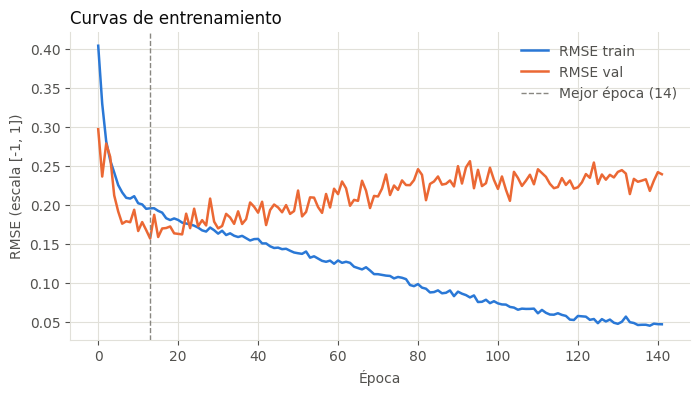

In [9]:
# Graficar curvas de entrenamiento y validación para verificar que no existe overfitting
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(historia['loss'], color=C_AZUL, lw=1.8, label='RMSE train')
ax.plot(historia['val_loss'], color=C_NARANJA, lw=1.8, label='RMSE val')
ax.axvline(mejor_epoca - 1, color=C_CRUDO, lw=1, ls='--', label=f'Mejor época ({mejor_epoca})')
estilo(ax, 'Curvas de entrenamiento', ylabel='RMSE (escala [-1, 1])')
ax.set_xlabel('Época', color=C_TINTA_2)
ax.legend(frameon=False, labelcolor=C_TINTA_2)
plt.show()

- Si la curva de validación empieza a subir mientras la de entrenamiento sigue bajando hay *overfitting*; el modelo restaurado corresponde a la mejor época de validación.
- Si ambas curvas siguen bajando al llegar a `EPOCHS`, el modelo aún no converge: se aumenta `EPOCHS` o la tasa de aprendizaje `LR`.

## 7. Desempeño del modelo

Se calcula el RMSE y el error absoluto medio (MAE) para train, val y test, **en mg/dL** (se invierte el escalamiento).

In [10]:
@torch.no_grad()
def predecir(x_s, modelo, scaler, batch=2048):
    '''Genera la predicción a HORIZONTE_MIN minutos con el modelo entrenado.

    Entrada:
    - x_s: ventanas de entrada ya escaladas, array o tensor de tamaño (VENTANAS, INPUT_LENGTH, FEATURES)
    - modelo: Red LSTM entrenada
    - scaler: escalador (para llevar la predicción a mg/dL)

    Salida:
    - y_pred: predicciones en mg/dL, arreglo de tamaño (VENTANAS, 1)
    '''
    modelo.eval()
    x = torch.as_tensor(x_s, dtype=torch.float32)
    salidas = [modelo(x[i:i + batch].to(DEVICE)).cpu() for i in range(0, len(x), batch)]
    y_pred_s = torch.cat(salidas).numpy()
    return scaler.inverse_transform(y_pred_s.reshape(-1, 1)).reshape(y_pred_s.shape)


def metricas(y_real, y_pred):
    '''RMSE y MAE (mg/dL), ignorando posiciones con NaN.'''
    y_real, y_pred = np.ravel(y_real), np.ravel(y_pred)
    ok = ~np.isnan(y_real) & ~np.isnan(y_pred)
    err = y_real[ok] - y_pred[ok]
    return np.sqrt(np.mean(err ** 2)), np.mean(np.abs(err))


# Predicciones del modelo (mg/dL)
y_tr_pred = predecir(x_tr_s, modelo, scaler)
y_vl_pred = predecir(x_vl_s, modelo, scaler)
y_ts_pred = predecir(x_ts_s, modelo, scaler)


resultados = pd.DataFrame(
    [metricas(y_tr, y_tr_pred),
     metricas(y_vl, y_vl_pred),
     metricas(y_ts, y_ts_pred)],

    index=['LSTM - train', 'LSTM - val', 'LSTM - test'],
    columns=['RMSE (mg/dL)', 'MAE (mg/dL)']).round(2)
resultados

,RMSE (mg/dL),MAE (mg/dL)
LSTM - train,31.40,25.00
LSTM - val,25.58,20.13
LSTM - test,40.44,31.18


In [11]:
# Evaluación contra la lectura CRUDA del sensor (sin suavizar) en el set de prueba.
# Las filas estimadas en interrupciones no tienen lectura cruda y se excluyen.
rmse_crudo, mae_crudo = metricas(y_ts_crudo, y_ts_pred)
n_validos = int((~np.isnan(y_ts_crudo)).sum())

print(f'Test contra lectura cruda del sensor a {HORIZONTE_MIN} min ({n_validos} de {len(y_ts_crudo)} ventanas con lectura real):')
print(f'  LSTM:         RMSE {rmse_crudo:.2f} mg/dL   MAE {mae_crudo:.2f} mg/dL')

Test contra lectura cruda del sensor a 30 min (659 de 676 ventanas con lectura real):
  LSTM:         RMSE 40.67 mg/dL   MAE 31.14 mg/dL


## 8. Predicciones con el modelo entrenado

Se compara gráficamente la glucosa real (suavizada) con la predicha por el modelo para cada dato del set de prueba. Cada predicción se genera en el instante t con las 2 horas previas de datos y corresponde a la glucosa en t + 30 min; en la gráfica se dibuja en ese instante futuro (t + 30 min), para compararla directamente con el valor real medido en ese momento.

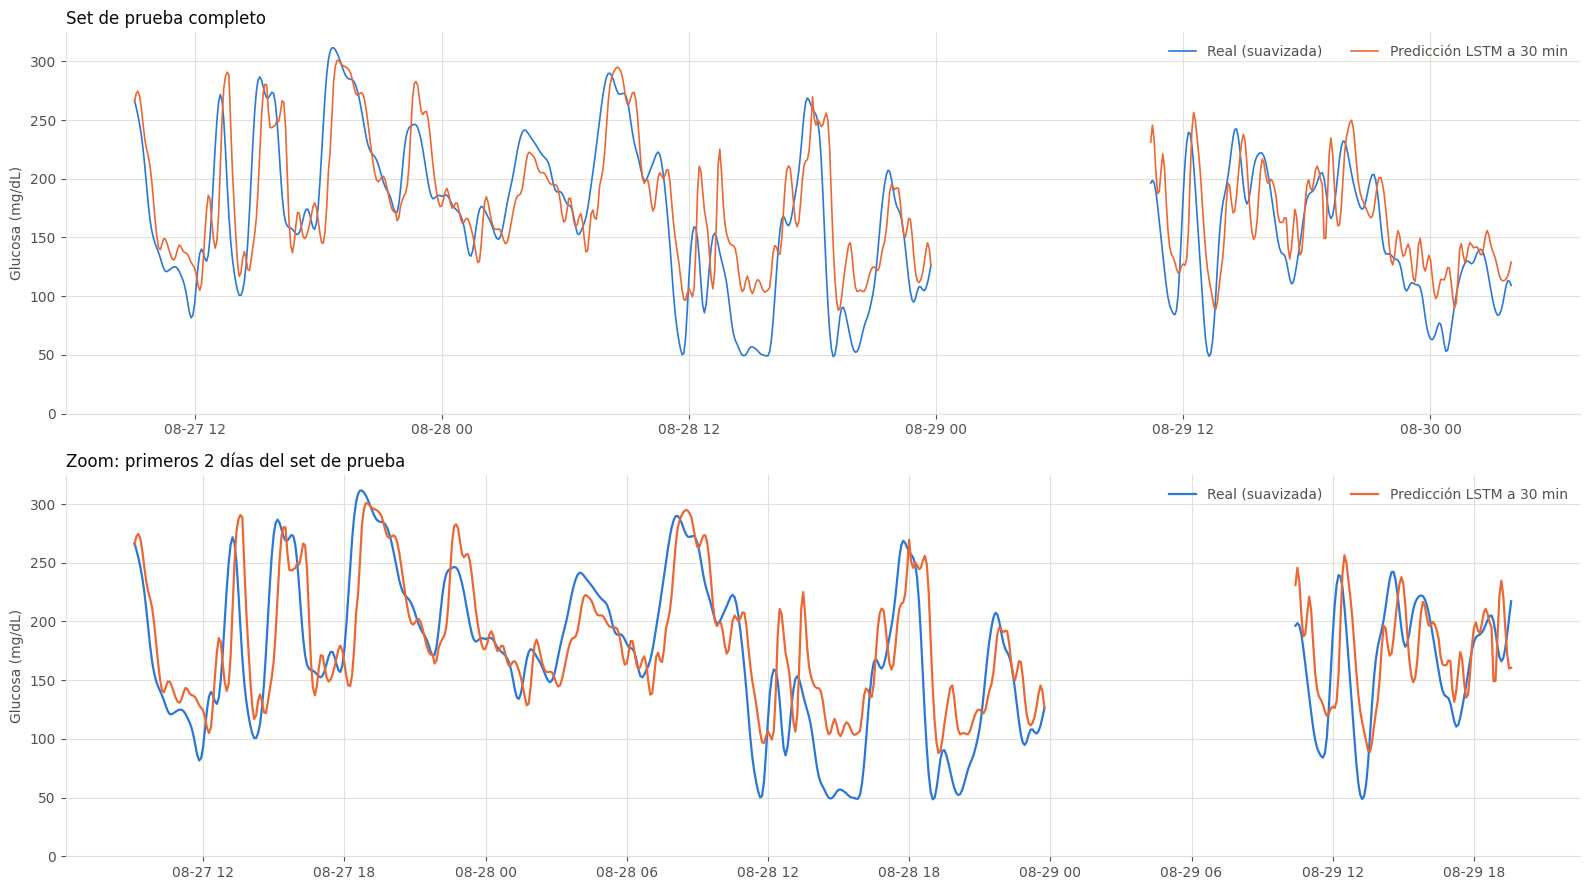

In [12]:
# Instante al que corresponde cada predicción (t + HORIZONTE_MIN)
t_pred = t_ts
assert len(t_pred) == len(y_ts_pred)

real_h = pd.Series(y_ts[:, -1], index=t_pred)
pred_h = pd.Series(y_ts_pred[:, -1], index=t_pred)

fig, axes = plt.subplots(2, 1, figsize=(16, 9))

ax = axes[0]
ax.plot(con_cortes(real_h), color=C_AZUL, lw=1.2, label='Real (suavizada)')
ax.plot(con_cortes(pred_h), color=C_NARANJA, lw=1.2, label=f'Predicción LSTM a {HORIZONTE_MIN} min')
estilo(ax, 'Set de prueba completo')
ax.set_ylim(bottom=0)
ax.legend(frameon=False, labelcolor=C_TINTA_2, ncol=2, loc='upper right')

# Zoom a los primeros 2 días del test
N_ZOOM = 2 * 24 * 60 // PASO_MIN
ax = axes[1]
ax.plot(con_cortes(real_h.iloc[:N_ZOOM]), color=C_AZUL, lw=1.6, label='Real (suavizada)')
ax.plot(con_cortes(pred_h.iloc[:N_ZOOM]), color=C_NARANJA, lw=1.6, label=f'Predicción LSTM a {HORIZONTE_MIN} min')
estilo(ax, 'Zoom: primeros 2 días del set de prueba')
ax.set_ylim(bottom=0)
ax.legend(frameon=False, labelcolor=C_TINTA_2, ncol=2, loc='upper right')

fig.tight_layout()
plt.show()

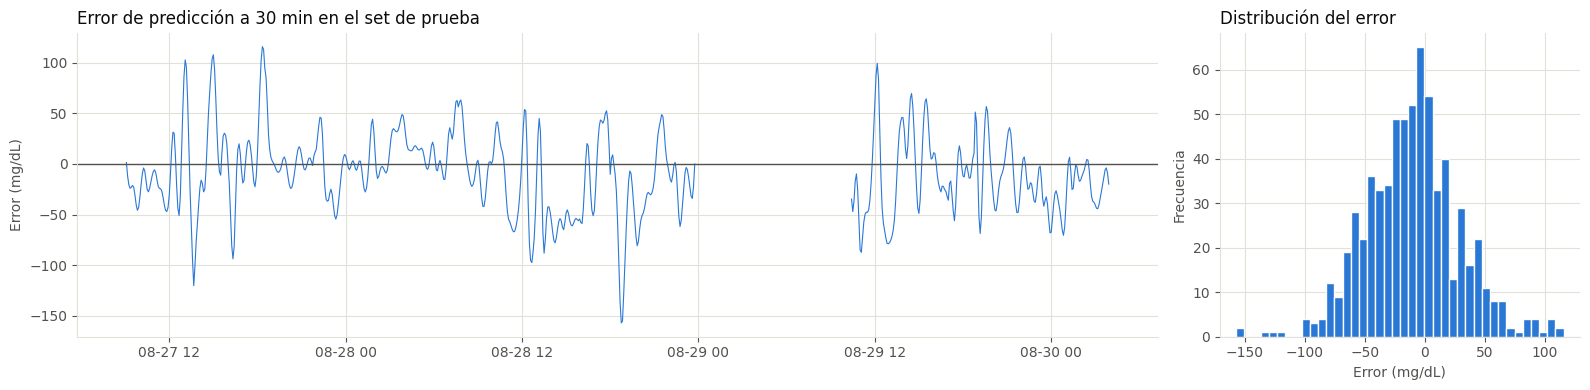

Error medio (sesgo): -10.18 mg/dL
Error mínimo / máximo: -157.0 / 115.8 mg/dL


In [13]:
# Errores simples (real - predicción) a HORIZONTE_MIN (30) min, en mg/dL
errores = y_ts[:, -1] - y_ts_pred[:, -1]

fig, axes = plt.subplots(1, 2, figsize=(16, 4), gridspec_kw={'width_ratios': [3, 1]})
axes[0].plot(con_cortes(pd.Series(errores, index=t_pred)), color=C_AZUL, lw=0.8)
axes[0].axhline(0, color=C_TINTA_2, lw=1)
estilo(axes[0], f'Error de predicción a {HORIZONTE_MIN} min en el set de prueba', ylabel='Error (mg/dL)')

axes[1].hist(errores, bins=40, color=C_AZUL, edgecolor='#fcfcfb')
estilo(axes[1], 'Distribución del error', ylabel='Frecuencia')
axes[1].set_xlabel('Error (mg/dL)', color=C_TINTA_2)

fig.tight_layout()
plt.show()

print(f'Error medio (sesgo): {errores.mean():.2f} mg/dL')
print(f'Error mínimo / máximo: {errores.min():.1f} / {errores.max():.1f} mg/dL')

In [14]:
# Guardar el modelo entrenado junto con lo necesario para reutilizarlo
ruta_modelo = RUTA_SALIDA + f'lstm_glucosa_bolus_carbohidratos_{PACIENTE}_{HORIZONTE_MIN}min.pt'
torch.save({
    'state_dict': modelo.state_dict(),
    'config': {'n_features': N_FEATURES, 'n_units': N_UNITS, 'input_length': INPUT_LENGTH,
               'horizonte_min': HORIZONTE_MIN, 'paso_min': PASO_MIN,
               'output_length': 1, 'paciente': PACIENTE,
               'feature_cols': FEATURE_COLS, 'target_col': COL},
    'scalers_min': [float(sc.data_min_[0]) for sc in scalers],   # un min/max por canal (orden de FEATURE_COLS)
    'scalers_max': [float(sc.data_max_[0]) for sc in scalers],
}, ruta_modelo)
print(f'Modelo guardado en: {ruta_modelo}')

Modelo guardado en: /gdrive/MyDrive/6_LSTM_DiabetesT1_Bolus_Carb_Pytorch/n001-smoothed/lstm_glucosa_bolus_carbohidratos_n001_30min.pt


## 9. Referencias
**Rabby et al. 2021.** Stacked LSTM based deep recurrent neural network with kalman smoothing for blood glucose, prediction. 2021. s.l. : BMC Medical Informatics and Decision Making, 2021, Vol. 21. https://doi.org/10.1186/s12911-021-01462-5.


**Sotaquirá, M.** Forecasting con Redes LSTM (parte 4): modelo univariado + multistep [video en línea]. Codificando Bits, 5 mayo 2023. [Consulta: 14 julio 2026]. Disponible en: https://www.youtube.com/watch?v=TEzTfl_E-3o
